# 03 - Visualização

**Objetivo:** mostrar o efeito da limpeza e o comportamento dos dados limpos.

**Lê:** `data/orignal/*.csv` (para o antes/depois) e `data/clean/*.parquet`  
**Gera:** figuras salvas em `reports/figures/`

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
original = Path("../data/original")
clean = Path("../data/clean")

# dados originais (para comparar antes/depois)
ratings_original = pd.read_csv(original / "Ratings.csv")
users_original = pd.read_csv(original / "Users.csv")
ratings_original['ISBN'] = ratings_original['ISBN'].astype(str)

# dados limpos
users = pd.read_parquet(clean / "users_clean.parquet")
books = pd.read_parquet(clean / "books_clean.parquet")
ratings = pd.read_parquet(clean / "ratings_clean.parquet")

## Antes vs depois da limpeza

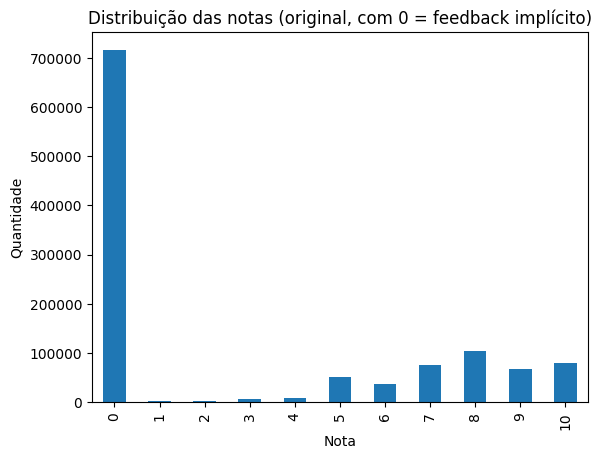

In [21]:
ratings_original['Book-Rating'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribuição das notas (original, com 0 = feedback implícito)')
plt.xlabel('Nota'); plt.ylabel('Quantidade')
plt.show()

como é possível ver no resultado do snippet acima, a incidencia da nota 0 é extremamente grande, mas isso se deve a forma como o dataset foi montado, nesse caso o zero não significa uma nota zero explicita, significa apenas que o usuario teve interação com o livro mas não o avaliou explicitamente.

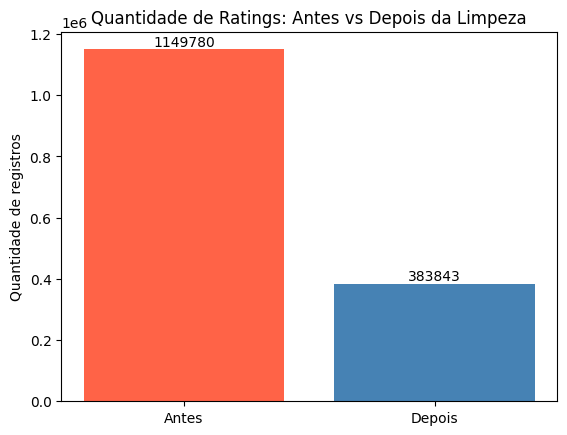

In [22]:
labels = ['Antes', 'Depois']
values = [ratings_original.shape[0], ratings.shape[0]]

plt.figure()
plt.bar(labels, values, color=['tomato', 'steelblue'])
plt.title('Quantidade de Ratings: Antes vs Depois da Limpeza')
plt.ylabel('Quantidade de registros')

for i, v in enumerate(values):
    plt.text(i, v + 10000, str(v), ha='center')

plt.show()

Figura 1. Quantidade de registros na tabela ratings antes (1.149.780) e depois (383.843) da limpeza, uma redução de 765.937 registros (cerca de 66,6%).

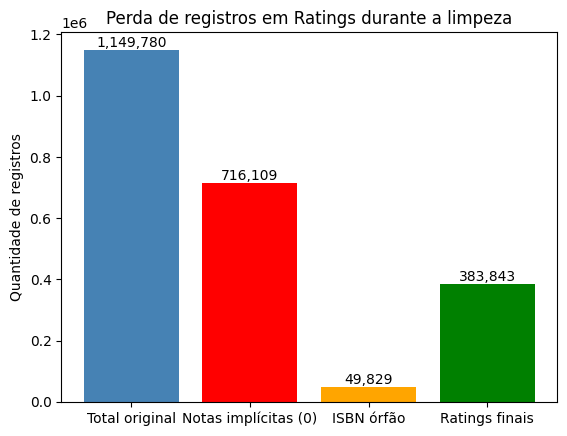

In [23]:
import matplotlib.pyplot as plt

# quantidade perdida em cada etapa
total_original = ratings_original.shape[0]
implicitos = (ratings_original['Book-Rating'] == 0).sum()
sem_implicitos = ratings_original[ratings_original['Book-Rating'] != 0]
orfaos = (~sem_implicitos['ISBN'].isin(books['ISBN'])).sum()
final = ratings.shape[0]

labels = ['Total original', 'Notas implícitas (0)', 'ISBN órfão', 'Ratings finais']
values = [total_original, implicitos, orfaos, final]
colors = ['steelblue', 'red', 'orange', 'green']

plt.figure()
bars = plt.bar(labels, values, color=colors)
plt.title('Perda de registros em Ratings durante a limpeza')
plt.ylabel('Quantidade de registros')

for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 10000, f'{v:,}', ha='center')

plt.show()

Figura 2. Registros removidos de ratings: 716.109 notas implícitas (nota 0) e 49.829 avaliações de ISBNs que não existem em books